# CASL-VAE: a cross-sectional 145-ROI example

Run the cells in order in the `caslvae` environment. This notebook uses the **original model and training loop in `code/`**. No covariate correction, covariate conditioning, temporal consistency, GRU, or flow is added.

A self-contained generator in the second code cell creates **one cross-sectional observation per subject*. Ground-truth subtype and severity are available for evaluation only. The original categorical salient encoder remains part of CASL-VAE; no additional subtype-prediction model is introduced.

Training runs for up to 500 epochs using the CASLVAE stopping rule. Results depend on initialization and the simulated disease burden; this notebook demonstrates the workflow rather than guarantees subtype recovery.


In [1]:
from pathlib import Path
import sys
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from torch.utils.data import DataLoader

# Works when opened from the repository root or docs/.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "code" / "CASLVAE_model.py").is_file())
sys.path.insert(0, str(ROOT / "code"))

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
OUTPUT = ROOT / "outputs" / "caslvae_cross_sectional_145roi_demo"
OUTPUT.mkdir(parents=True, exist_ok=True)
print("Device:", DEVICE)


c:\Anaconda3\envs\normative\lib\site-packages\tqdm\auto.py:22: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Device: cuda


## 1. Generate cross-sectional samples

The simulator creates individual anatomy, normal aging, two non-overlapping disease patterns, and measurement noise. Each disease pattern affects 43 of the 145 ROIs. Disease effect equals the pattern multiplied by simulated severity.

Subjects are sampled directly as reference (50%), target subtype 1 (25%), or target subtype 2 (25%). No visits, converters, or trajectories are generated. Age/sex/ICV variation remains in the observations because we disable covariate correction. These variables are not passed to the model.


In [2]:
def generate_cross_sectional_rois(n_subjects=600, n_rois=145, seed=42):
    """One observation per subject; two disjoint target patterns."""
    if n_subjects < 30 or n_rois < 4:
        raise ValueError("Use at least 30 subjects and 4 ROIs")
    rng = np.random.default_rng(seed)
    features = [f"ROI_{j+1:02d}" for j in range(n_rois)]
    mean = rng.uniform(2500, 6000, n_rois)
    baseline_sd = .10 * mean
    aging_slope = -rng.uniform(.002, .015, n_rois) * mean

    affected = max(1, int(.30 * n_rois))
    selected = rng.permutation(n_rois)
    roi_sets = [selected[:affected], selected[affected:2*affected]]
    patterns = np.zeros((2, n_rois))
    for k, indices in enumerate(roi_sets):
        patterns[k, indices] = -rng.uniform(.01, .03, len(indices)) * mean[indices]

    category = rng.choice(3, size=n_subjects, p=[.50, .25, .25])
    age = rng.uniform(50, 80, n_subjects)
    sex = rng.integers(2, size=n_subjects)
    icv = rng.normal(size=n_subjects)
    anatomy = (rng.normal(mean, baseline_sd, (n_subjects, n_rois))
               + .03 * mean * (sex[:, None] - .5)
               + .08 * mean * icv[:, None])
    slopes = aging_slope * rng.lognormal(-.5 * .3**2, .3, (n_subjects, n_rois))
    healthy = anatomy + (age[:, None] - 60.) * slopes

    severity = rng.uniform(1., 8., n_subjects) * rng.uniform(.7, 1.3, n_subjects)
    severity[category == 0] = 0.
    effect = np.zeros_like(healthy)
    for k in (1, 2):
        mask = category == k
        effect[mask] = severity[mask, None] * patterns[k-1]
    noise = rng.normal(0, .01 * mean, healthy.shape)
    observed = healthy + effect + noise
    if (observed <= 0).any():
        raise ValueError("Nonpositive volume: reduce severity or age range")

    frame = pd.DataFrame(observed.astype(np.float32), columns=features)
    frame.insert(0, "subject_id", [f"s{i}" for i in range(n_subjects)])
    frame["label"] = np.where(category == 0, "Background", "Target")
    frame["true_category"] = category
    frame["age"], frame["sex"], frame["icv"] = age, sex, icv
    frame["severity"] = severity
    population = dict(
        disease_pattern1=patterns[0], disease_pattern2=patterns[1],
        pattern1_rois=roi_sets[0], pattern2_rois=roi_sets[1],
        mu_hc=mean, beta_age=aging_slope,
    )
    return frame, population, effect.astype(np.float32), healthy.astype(np.float32)


data, population, true_effects, true_healthy = generate_cross_sectional_rois(n_rois=145, seed=SEED)
features = [column for column in data.columns if column.startswith("ROI_")]

# Subject-disjoint partitions: one row already corresponds to one subject.
train_index, heldout_index = train_test_split(
    np.arange(len(data)), test_size=0.30, random_state=SEED,
    stratify=data["true_category"],
)
val_index, test_index = train_test_split(
    heldout_index, test_size=0.50, random_state=SEED,
    stratify=data.iloc[heldout_index]["true_category"],
)
data["split"] = ""
for name, indices in [("train", train_index), ("validation", val_index), ("test", test_index)]:
    data.loc[indices, "split"] = name
data.to_csv(OUTPUT / "synthetic_cross_sectional.csv", index=False)
np.savez_compressed(OUTPUT / "synthetic_truth.npz",
                    disease_effect=true_effects, healthy=true_healthy)
display(pd.crosstab(data["split"], data["true_category"]).rename(
    columns={0: "Reference", 1: "Target subtype 1", 2: "Target subtype 2"}))


true_category,Reference,Target subtype 1,Target subtype 2
split,,,
test,46,22,22
train,213,104,103
validation,46,22,22


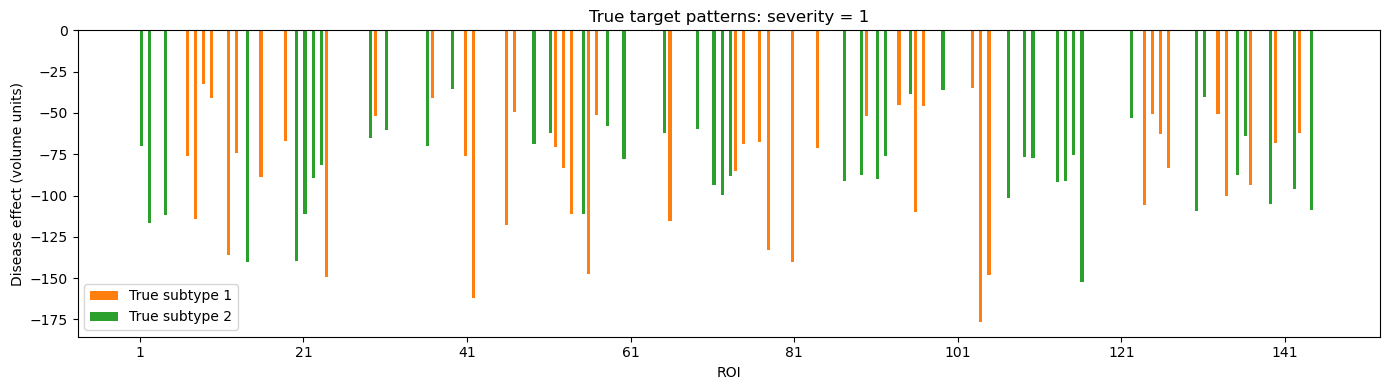

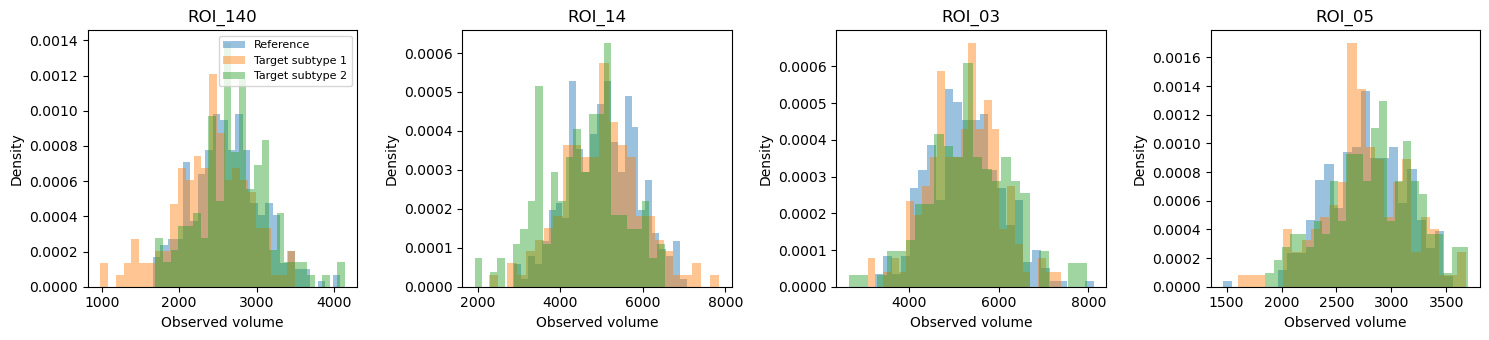

In [3]:
colors = ["tab:blue", "tab:orange", "tab:green"]
names = ["Reference", "Target subtype 1", "Target subtype 2"]
patterns = np.stack([population["disease_pattern1"], population["disease_pattern2"]])

fig, ax = plt.subplots(figsize=(14, 4))
roi_axis = np.arange(1, len(features)+1)
for k in range(2):
    ax.bar(roi_axis + (k-.5)*.38, patterns[k], width=.38,
           color=colors[k+1], label=f"True subtype {k+1}")
ax.axhline(0, color="black", lw=.7)
ax.set(title="True target patterns: severity = 1", xlabel="ROI",
       ylabel="Disease effect (volume units)", xticks=np.arange(1, len(features)+1, 20))
ax.legend()
fig.tight_layout()
plt.show()

# Include one affected ROI per subtype and two unaffected ROIs.
affected = list(population["pattern1_rois"]) + list(population["pattern2_rois"])
unaffected = [j for j in range(len(features)) if j not in affected]
example_rois = [int(population["pattern1_rois"][0]),
                int(population["pattern2_rois"][0]), *unaffected[:2]]
fig, axes = plt.subplots(1, 4, figsize=(15, 3.5))
for ax, roi in zip(axes, example_rois):
    for k in range(3):
        values = data.loc[data["true_category"].eq(k), features[roi]]
        ax.hist(values, bins=25, density=True, alpha=.45, color=colors[k], label=names[k])
    ax.set(title=features[roi], xlabel="Observed volume", ylabel="Density")
axes[0].legend(fontsize=8)
fig.tight_layout()
plt.show()


## 2. Create the original CASL-VAE

As in the research scripts: import `CASLVAE`, preprocess the data, build unpaired datasets, call `create(opt)`, and attach preprocessing parameters.

Only the 145 ROI measurements enter the model. Preprocessing is fitted on **training reference samples only**. Subtype labels are used to balance simulation partitions and visualize results, never to train the model.


In [4]:
from CASLVAE_model import CASLVAE
from data_utils import PreprocessingStats, PreprocessingTransform, CreateDataset
from train_utils import train_model

train_df = data.iloc[train_index]
stats = PreprocessingStats(
    train_df[features].to_numpy(), train_df["label"].to_numpy(),
    covariate_correct=False,
)
stats.stats()

def transform(indices):
    return PreprocessingTransform(
        data.iloc[indices][features].to_numpy(), stats, covariate_correct=False,
    ).transform().astype(np.float32)

train_x, val_x, test_x = [transform(i) for i in (train_index, val_index, test_index)]
train_dataset = CreateDataset(train_x, data.iloc[train_index]["label"].to_numpy())
val_dataset = CreateDataset(val_x, data.iloc[val_index]["label"].to_numpy())

opt = dict(
    nfeatures=len(features), nLatent_z=15, nLatent_s_cont=2,
    nLatent_s_cat=1, ncategories=3,
    mmd_lambda=100, kl_z_lambda=1, kl_scat_lambda=1,
    kl_scont_lambda=1, kl_sconty_lambda=1,
    consistency_lambda=10, entropy_lambda=1, norm_salienty_lambda=0,
    lr=.001, beta1=.5, scheduler=False, decay_epochs=1,
    DEVICE=DEVICE, epochs=500, batch_size=128, path=str(OUTPUT),
)
loader = DataLoader(train_dataset, batch_size=opt["batch_size"], shuffle=True,
                    generator=torch.Generator().manual_seed(SEED))
model = CASLVAE()
model.create(opt=opt)
model.set_preprocessing_params(dict(
    data_mean=stats.data_mean, data_std=stats.data_std,
    cov_min=None, cov_max=None, cov_beta=None, covariate_correct=False,
    feature_names=features, covariate_names=[], tau=1.,
))
print(type(model.G_forward).__name__)
print("Features only; no covariates or subtype ground truth supplied.")


Generator_CASL_twodecoders
Features only; no covariates or subtype ground truth supplied.


## 3. Train

This cell performs training; skip it if a checkpoint already exists. The original loop saves `model_checkpoint.pt` when its stopping rule triggers or the epoch budget ends. It does not restore the minimum-BCE or minimum-reconstruction epoch. The next cell reloads what was actually saved.

The loop's diagnostic panels assume at least eight input features; this example has 145.


In [ ]:
def tensor(values):
    return torch.as_tensor(values, dtype=torch.float32, device=DEVICE)

model, clustering_logits, loss_history, converged = train_model(
    model, opt, loader,
    tensor(train_dataset.data_bg), tensor(train_dataset.data_tgt),
    tensor(val_dataset.data_bg), tensor(val_dataset.data_tgt),
)
print("Original stopping rule triggered:", converged)


## 4. Load the checkpoint and evaluate held-out subjects

Inference uses common posterior means, hard categorical assignments, and the continuous salient encoder output. These are deterministic summaries, unlike sampled latents used during training. Reference samples use the model's reference salient preset for reconstruction; target samples use inferred codes.

The same common latent with the reference salient preset gives a paired reference estimate. It is not guaranteed to equal the simulator's true individual healthy anatomy.


In [6]:
model = CASLVAE()
checkpoint = model.load_model(str(OUTPUT / "model_checkpoint.pt"), device=DEVICE)
g = model.G_forward
g.eval()

# Reapply saved preprocessing rather than fitting anything on test subjects.
def saved_transform(indices):
    raw = data.iloc[indices][model.feature_names].to_numpy()
    return ((raw - model.train_mean) / (model.train_std + 1e-6)).astype(np.float32)

with torch.no_grad():
    x = tensor(saved_transform(test_index))
    z, _ = g.encode_common(x)
    logits, salient_features = g.encode_salient_cat(x)
    probabilities = logits.softmax(-1)
    inferred_category = probabilities.argmax(-1)
    code = torch.nn.functional.one_hot(inferred_category, opt["ncategories"]).to(x.dtype)
    reference_code = torch.zeros_like(code)
    reference_code[:, 0] = 1
    is_reference = tensor(data.iloc[test_index]["label"].eq("Background").to_numpy()).bool()
    reconstruction_code = torch.where(is_reference[:, None], reference_code, code)
    s_cont = g.enc_s_cont(torch.cat([salient_features, reconstruction_code], dim=1))
    reconstruction_s = torch.where(is_reference[:, None], torch.zeros_like(s_cont), s_cont)
    common = g.decode_common(z)
    reconstruction = common + g.decode_salient(reconstruction_code, reconstruction_s)
    paired_reference = common + g.decode_salient(reference_code, torch.zeros_like(s_cont))

scale = np.asarray(model.train_std) + 1e-6
reconstruction_raw = reconstruction.cpu().numpy() * scale + model.train_mean
paired_raw = paired_reference.cpu().numpy() * scale + model.train_mean
observed = data.iloc[test_index][features].to_numpy()
truth = data.iloc[test_index]["true_category"].to_numpy()
print("Saved epoch (loop index):", checkpoint["epoch"], "| temperature:", checkpoint["tau"])
print("Test reconstruction MAE:", round(float(abs(reconstruction_raw-observed).mean()), 2))
print("Paired reference vs true healthy MAE:",
      round(float(abs(paired_raw-true_healthy[test_index]).mean()), 2))
np.savez_compressed(OUTPUT / "test_outputs.npz",
                    subject_id=data.iloc[test_index]["subject_id"].to_numpy(dtype=str),
                    probabilities=probabilities.cpu().numpy(), z=z.cpu().numpy(),
                    s_cont=s_cont.cpu().numpy(), reconstruction=reconstruction_raw,
                    paired_reference=paired_raw, true_category=truth)


Saved epoch (loop index): 305 | temperature: 0.4855933748302038
Test reconstruction MAE: 349.42
Paired reference vs true healthy MAE: 351.24


## 5. Prototypical target patterns

For each target category, decode its learned continuous salient **prior mean** and subtract the reference salient preset. The common term cancels. Multiply differences by the saved feature standard deviations; do not add the feature mean.

The ground-truth patterns above are defined at severity 1. Learned prior prototypes have their own learned magnitude, so their amplitudes need not match. Category 1/2 labels can be permuted relative to the simulated subtypes.


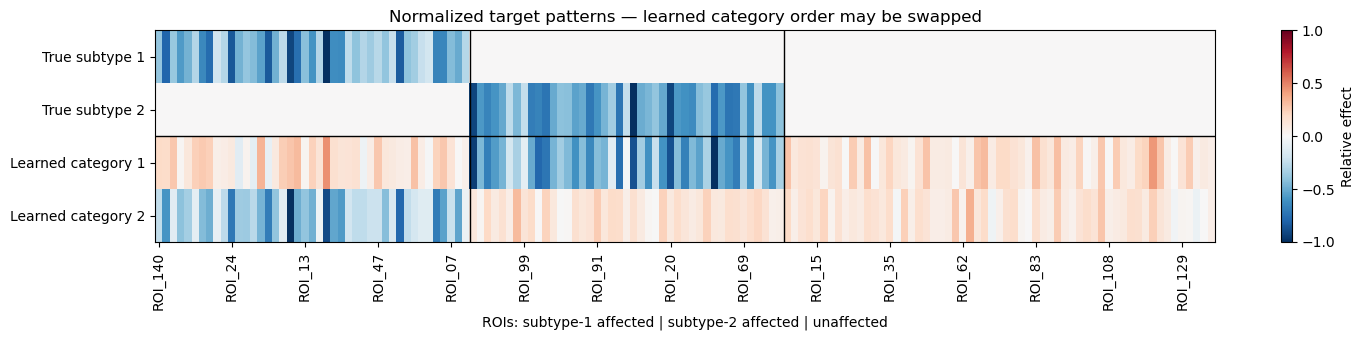

In [13]:
with torch.no_grad():
    target_codes = torch.eye(opt["ncategories"], device=DEVICE)[1:]
    prior_s = g.prior_s_cont(target_codes)
    ref_codes = torch.zeros_like(target_codes)
    ref_codes[:, 0] = 1
    prototypes = (g.decode_salient(target_codes, prior_s)
                  - g.decode_salient(ref_codes, torch.zeros_like(prior_s)))
prototypes = prototypes.cpu().numpy() * scale

# plot the groud truth patterns vs learned prototypical patterns
group1 = list(population["pattern1_rois"])
group2 = list(population["pattern2_rois"])
unaffected = [
    j for j in range(len(features))
    if j not in group1 + group2
]
order = group1 + group2 + unaffected

values = np.vstack([patterns, prototypes])[:, order]
normalized = values / np.maximum(
    np.abs(values).max(axis=1, keepdims=True), 1e-8
)

fig, ax = plt.subplots(figsize=(15, 3.5))
image = ax.imshow(
    normalized, aspect="auto", cmap="RdBu_r",
    vmin=-1, vmax=1, interpolation="nearest",
)
ax.set_yticks(range(4))
ax.set_yticklabels([
    "True subtype 1", "True subtype 2",
    "Learned category 1", "Learned category 2",
])
ax.axhline(1.5, color="black", linewidth=1)

for boundary in [len(group1), len(group1) + len(group2)]:
    ax.axvline(boundary - .5, color="black", linewidth=1)

ticks = np.arange(0, len(order), 10)
ax.set_xticks(ticks)
ax.set_xticklabels([features[order[j]] for j in ticks], rotation=90)
ax.set_xlabel("ROIs: subtype-1 affected | subtype-2 affected | unaffected")
ax.set_title("Normalized target patterns — learned category order may be swapped")
fig.colorbar(image, ax=ax, label="Relative effect")
fig.tight_layout()
plt.show()

## 6. Inspect continuous salient and common representations

The common latent is 15-dimensional; PCA is fitted on **training common embeddings** and applied to test embeddings. The salient latent is already two-dimensional. Reference salient codes are preset to zero by the model; the salient scatter therefore shows target subjects only.

Coloring by simulator truth helps assess separation and leakage; it does not supervise training. Neither a PCA plot nor visual separation proves disentanglement.


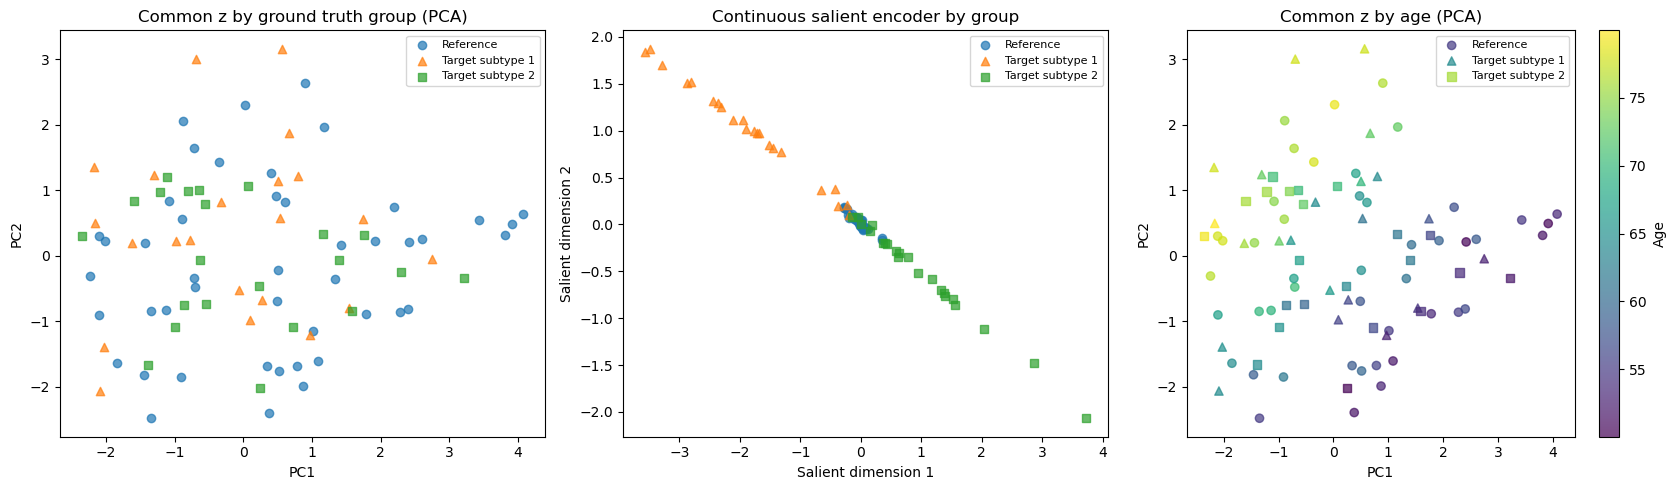

In [21]:
with torch.no_grad():
    train_z, _ = g.encode_common(tensor(saved_transform(train_index)))
    s_all = g.enc_s_cont(
        torch.cat([salient_features, code], dim=1)
    ).cpu().numpy()

pca = PCA(n_components=2).fit(train_z.cpu().numpy())
z_plot = pca.transform(z.cpu().numpy())
ages = data.iloc[test_index]["age"].to_numpy()

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for k, marker in enumerate(["o", "^", "s"]):
    mask = truth == k
    for ax, embedding in zip(axes[:2], [z_plot, s_all]):
        ax.scatter(
            embedding[mask, 0], embedding[mask, 1],
            color=colors[k], marker=marker,
            alpha=.7, label=names[k],
        )

axes[0].set(title="Common z by ground truth group (PCA)", xlabel="PC1", ylabel="PC2")
axes[1].set(
    title="Continuous salient encoder by group",
    xlabel="Salient dimension 1", ylabel="Salient dimension 2",
)

# Shared age scale; marker shapes still distinguish groups.
age_norm = plt.Normalize(ages.min(), ages.max())
for k, marker in enumerate(["o", "^", "s"]):
    mask = truth == k
    scatter = axes[2].scatter(
        z_plot[mask, 0], z_plot[mask, 1],
        c=ages[mask], cmap="viridis", norm=age_norm,
        marker=marker, alpha=.7, label=names[k],
    )

axes[2].set(title="Common z by age (PCA)", xlabel="PC1", ylabel="PC2")
fig.colorbar(scatter, ax=axes[2], label="Age")

for ax in axes:
    ax.legend(fontsize=8)

fig.tight_layout()
plt.show()

All outputs are under `outputs/caslvae_cross_sectional_demo/`. Ground-truth effects, subtype labels, and healthy counterparts are retained for evaluation only. This notebook does not perform longitudinal forecasting or change the original CASL-VAE objective.

See [the experiment guide](experiments.md) for category-count selection and training behavior, and [the usage guide](usage.md) for generation and output interpretation.
